In [1]:
import os
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import fdrcorrection
import scikit_posthocs as sp
from statannotations.Annotator import Annotator
from itertools import combinations
import warnings

import sys
sys.path.append('/root/capsule/code/figures')
from core_utils import get_seaad_colors, format_box_plot

sns.set_context('notebook')
plt.rcParams['pdf.fonttype'] = 42
warnings.filterwarnings('ignore')

# Cell depth from cut surface analysis

Analysis of cell depth from the cut surface of brain slices across species and subclasses.

In [2]:
# Output directory
OUT_DIR = Path('/root/capsule/scratch/20260807/slice_surface_depth')
os.makedirs(OUT_DIR, exist_ok=True)

DATA_ROOT = Path('/root/capsule/data')

# Cell depth data
human_depth_file = DATA_ROOT / 'human' / 'slice_surface_depth' / '20260921' / 'cell_depth_from_cut_surface.csv'
macaque_depth_file = DATA_ROOT / 'macaque' / 'slice_surface_depth' / '20260921' / 'cell_depth_from_cut_surface.csv'
mouse_depth_file = DATA_ROOT / 'mouse' / 'slice_surface_depth' / '20260921' / 'cell_depth_from_cut_surface.csv'

# Metadata
human_metadata_file = DATA_ROOT / 'human' / 'metadata' / '20260807' / 'human_metadata.csv'
macaque_metadata_file = DATA_ROOT / 'macaque' / 'metadata' / '20260722' / 'macaque_metadata.csv'
mouse_metadata_file = DATA_ROOT / 'mouse' / 'metadata' / '20260826' / 'mouse_metadata.csv'

# Color file
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'

print('Paths configured')

Paths configured


In [3]:
# Load cell depth data and normalize species names to lowercase
human_depth = pd.read_csv(human_depth_file)
human_depth['species'] = human_depth['species'].str.lower()

macaque_depth = pd.read_csv(macaque_depth_file)
macaque_depth['species'] = macaque_depth['species'].str.lower()

mouse_depth = pd.read_csv(mouse_depth_file)
mouse_depth['species'] = mouse_depth['species'].str.lower()

print(f'Human depth data: {len(human_depth)} cells')
print(f'Macaque depth data: {len(macaque_depth)} cells')
print(f'Mouse depth data: {len(mouse_depth)} cells')

Human depth data: 368 cells
Macaque depth data: 51 cells
Mouse depth data: 29 cells


In [4]:
# Load metadata
human_metadata = pd.read_csv(human_metadata_file)
human_metadata['cell_id'] = human_metadata['cell_id'].fillna(-1).astype(int)
human_metadata = human_metadata[human_metadata['cell_id'] != -1]
human_metadata = human_metadata.rename(columns={'cell_id': 'specimen_id', 'subclass_label_Hierarchical': 'subclass'})
human_metadata = human_metadata[['specimen_id', 'subclass']]

macaque_metadata = pd.read_csv(macaque_metadata_file)
macaque_metadata = macaque_metadata.rename(columns={'subclass_Corr_label_RSC_204_389': 'subclass'})
macaque_metadata = macaque_metadata[['specimen_id', 'subclass']]

mouse_metadata = pd.read_csv(mouse_metadata_file)
mouse_metadata['subclass'] = mouse_metadata['subclass'].str.replace('_', ' ')
mouse_metadata = mouse_metadata[['specimen_id', 'subclass']]

print(f'Human metadata: {len(human_metadata)} cells')
print(f'Macaque metadata: {len(macaque_metadata)} cells')
print(f'Mouse metadata: {len(mouse_metadata)} cells')

Human metadata: 1511 cells
Macaque metadata: 51 cells
Mouse metadata: 29 cells


In [5]:
# Merge depth data with metadata
human_data = human_depth.merge(human_metadata, on='specimen_id', how='left')
macaque_data = macaque_depth.merge(macaque_metadata, on='specimen_id', how='left')
mouse_data = mouse_depth.merge(mouse_metadata, on='specimen_id', how='left')

# Combine all data
all_data = pd.concat([human_data, macaque_data, mouse_data], ignore_index=True)

print(f'Total combined data: {len(all_data)} cells')
print(f'\nSpecies distribution:')
print(all_data['species'].value_counts())
print(f'\nSubclass distribution:')
print(all_data['subclass'].value_counts())

Total combined data: 448 cells

Species distribution:
human      368
macaque     51
mouse       29
Name: species, dtype: int64

Subclass distribution:
L2/3 IT       167
L5 IT          83
L4 IT          81
L5/6 NP        23
L5 ET          23
L6 IT          21
L6 IT Car3     17
L6 CT          13
L6b             9
L2-3 IT         6
L5 ET(ME)       5
Name: subclass, dtype: int64


In [6]:
# Convert negative cell_depths to absolute values
print(f'\nBefore filtering: {len(all_data)} cells')
print(f'Cells with negative depth: {len(all_data[all_data["cell_depth"] < 0])}')

all_data['cell_depth'] = all_data['cell_depth'].abs()
print(f'After converting to absolute values: {len(all_data)} cells')

# Filter out cell_depths > 350 (avg slice thickness)
print(f'Cells with depth > 350: {len(all_data[all_data["cell_depth"] > 350])}')
all_data = all_data[all_data['cell_depth'] <= 350].copy()

print(f'After filtering (depth <= 350): {len(all_data)} cells')


Before filtering: 448 cells
Cells with negative depth: 11
After converting to absolute values: 448 cells
Cells with depth > 350: 2
After filtering (depth <= 350): 446 cells


In [7]:
# Load colors
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))

subclass_colors = get_seaad_colors()

species_order = ['human', 'macaque', 'mouse']

print('Species colors:', species_colors)

Species colors: {'human': '#377eb8', 'macaque': '#4daf4a', 'mouse': '#c941a7'}


## Analysis 1: Human data - cell_depth x subclass

In [8]:
# Filter to human data only
human_only = all_data[all_data['species'] == 'human'].copy()
human_only = human_only.dropna(subset=['subclass', 'cell_depth'])

# Get subclass order (sorted by sample size)
subclass_counts = human_only['subclass'].value_counts()
human_subclass_order = subclass_counts.index.tolist()
human_subclass_order = [s for s in human_subclass_order if subclass_counts[s] >= 3]

print(f'Human data: {len(human_only)} cells across {len(human_subclass_order)} subclasses')
print(f'\nSubclass counts:')
print(human_only['subclass'].value_counts())

Human data: 366 cells across 10 subclasses

Subclass counts:
L2/3 IT       148
L4 IT          78
L5 IT          57
L5/6 NP        19
L6 IT Car3     17
L6 IT          17
L6 CT          12
L6b             7
L5 ET           6
L5 ET(ME)       5
Name: subclass, dtype: int64


In [9]:
# Run Kruskal-Wallis test across all subclasses
subclass_groups = [human_only[human_only['subclass'] == sc]['cell_depth'].dropna().tolist()
                   for sc in human_subclass_order]
subclass_groups = [g for g in subclass_groups if len(g) > 0]

sig_pairs = []  # Initialize to ensure it exists for plotting
stats_results = []  # Store statistics for CSV

if len(subclass_groups) > 2:
    stat, pval = kruskal(*subclass_groups, nan_policy='omit')

    # Store overall test result
    stats_results.append({
        'test': 'Kruskal-Wallis',
        'group1': 'all',
        'group2': 'all',
        'pval': pval,
        'pval_fdr': pval,  # No multiple correction for single omnibus test
        'significant': pval < 0.05
    })

    print(f'Kruskal-Wallis test across all subclasses:')
    print(f'  Statistic: {stat:.4f}')
    print(f'  P-value: {pval:.4e}')

    if pval < 0.05:
        print(f'  => Significant difference detected (p < 0.05)')

        # Run Dunn posthoc test
        posthoc = sp.posthoc_dunn(subclass_groups, p_adjust='fdr_bh')
        print(f'\n  Posthoc Dunn test (FDR corrected):')

        for i, j in combinations(range(len(human_subclass_order)), 2):
            p = posthoc.iloc[i, j]
            stats_results.append({
                'test': 'Dunn posthoc (FDR)',
                'group1': human_subclass_order[i],
                'group2': human_subclass_order[j],
                'pval': p,
                'pval_fdr': p,
                'significant': p < 0.05
            })
            if p < 0.05:
                sig_pairs.append((human_subclass_order[i], human_subclass_order[j], p))

        if sig_pairs:
            print(f'  Found {len(sig_pairs)} significant pairwise comparisons')
            print(f'  (Showing first 10):')
            for s1, s2, p in sig_pairs[:10]:
                print(f'    {s1} vs {s2}: p = {p:.4e}')
        else:
            print(f'  No significant pairwise comparisons after FDR correction.')
    else:
        print(f'  => No significant difference (p >= 0.05)')

Kruskal-Wallis test across all subclasses:
  Statistic: 74.3174
  P-value: 2.1550e-12
  => Significant difference detected (p < 0.05)

  Posthoc Dunn test (FDR corrected):
  Found 13 significant pairwise comparisons
  (Showing first 10):
    L2/3 IT vs L4 IT: p = 2.7616e-10
    L2/3 IT vs L5 IT: p = 1.5419e-02
    L4 IT vs L5 IT: p = 1.6572e-02
    L4 IT vs L5/6 NP: p = 7.1949e-03
    L4 IT vs L6 IT Car3: p = 3.6880e-02
    L4 IT vs L6 IT: p = 8.0535e-04
    L4 IT vs L6 CT: p = 4.2151e-05
    L4 IT vs L6b: p = 1.5469e-02
    L4 IT vs L5 ET: p = 1.1016e-04
    L4 IT vs L5 ET(ME): p = 5.8056e-03


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:2.762e-10
L4 IT vs. L5 IT: Custom statistical test, P_val:1.657e-02
L2/3 IT vs. L5 IT: Custom statistical test, P_val:1.542e-02
L4 IT vs. L5/6 NP: Custom statistical test, P_val:7.195e-03
L4 IT vs. L6 IT Car3: Custom statistical test, P_val:3.688e-02
L4 IT vs. L6 IT: Custom statistical test, P_val:8.054e-04
L5 IT vs. L6 CT: Custom statistical test, P_val:1.177e-02
L6 IT Car3 vs. L5 ET: Custom statistical test, P_val:3.688e-02
L4 IT vs. L6 CT: Custom statistical test, P_val:4.215e-05
L4 IT vs. L6b: Custom statistical test, P_val:1.547e-02
L5 IT vs. L5 ET: Custom statistical test, P_val:7.195e-03
L4 IT vs. L5 ET: Custom statistical test, P_val:1.102e-04
L4 IT vs. L5 ET(ME): Custom statistical test, P_val:5.806e-03


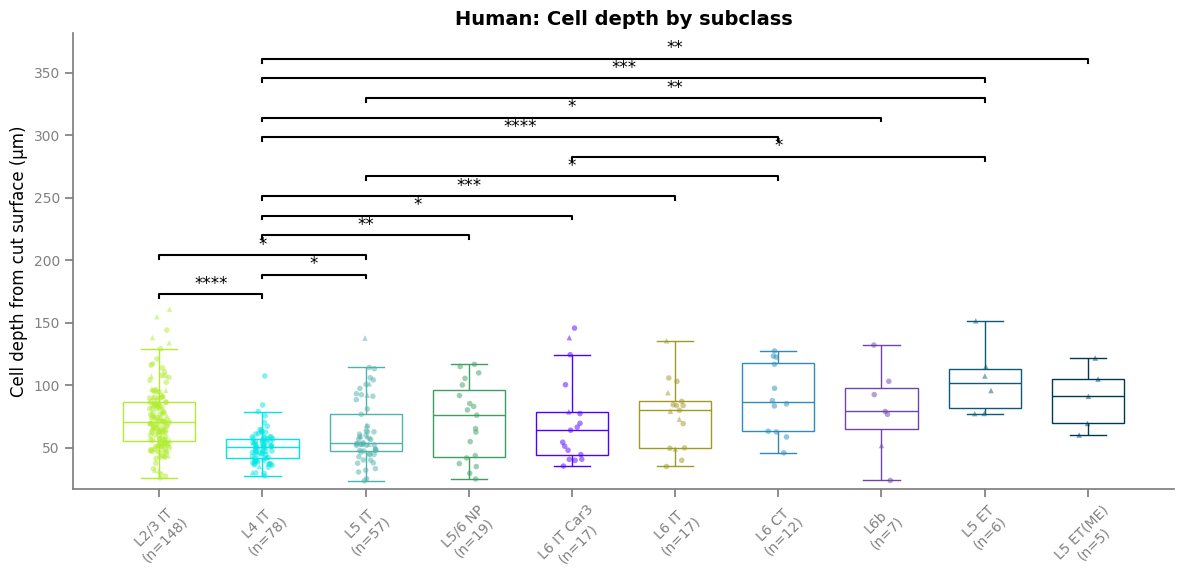


Saved: /root/capsule/scratch/20260807/slice_surface_depth/human_cell_depth_by_subclass.pdf
Saved: /root/capsule/scratch/20260807/slice_surface_depth/human_cell_depth_by_subclass_stats.csv


In [10]:
# Plot
fig, ax = plt.subplots(figsize=(12, 6))

# Plot stripplot with different markers for each method
for method, marker in [('lims', 'o'), ('estimated', '^')]:
    method_data = human_only[human_only['method'] == method]
    if len(method_data) > 0:
        sns.stripplot(data=method_data, x='subclass', y='cell_depth', hue='subclass',
                     palette=subclass_colors, order=human_subclass_order, legend=False,
                     alpha=0.5, size=4, ax=ax, marker=marker)

sns.boxplot(data=human_only, x='subclass', y='cell_depth', hue='subclass',
           palette=subclass_colors, order=human_subclass_order, legend=False,
           saturation=1, linewidth=1, width=0.7, showfliers=False, ax=ax)
format_box_plot(ax)

# Add statistical annotations from Dunn post-hoc test
if sig_pairs:
    pairs = [(s1, s2) for s1, s2, p in sig_pairs]
    pvals_annot = [p for s1, s2, p in sig_pairs]
    
    annotator = Annotator(ax, pairs, data=human_only, x='subclass', y='cell_depth', order=human_subclass_order)
    annotator.configure(test=None, text_format='star', loc='inside', color='black')
    annotator.set_pvalues(pvals_annot)
    annotator.annotate()

sns.despine(right=True, top=True)
ax.set_xlabel(None)
ax.set_ylabel('Cell depth from cut surface (µm)', rotation=90, size=12)
ax.set_title('Human: Cell depth by subclass', size=14, weight='bold')
ax.tick_params(axis='x', rotation=45, labelsize=10)
ax.tick_params(axis='y', labelsize=10)

nobs = [f"{sc}\n(n={subclass_counts[sc]})" for sc in human_subclass_order]
ax.set_xticklabels(nobs, fontsize=10)

ax.tick_params(axis='both', colors='grey')
ax.xaxis.set_tick_params(labelcolor='grey')
ax.spines['bottom'].set_color('grey')
ax.spines['left'].set_color('grey')

plt.tight_layout()
plt.savefig(OUT_DIR / 'human_cell_depth_by_subclass.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Save statistics results instead of raw data
stats_df = pd.DataFrame(stats_results)
stats_df.to_csv(OUT_DIR / 'human_cell_depth_by_subclass_stats.csv', index=False)
print(f'\nSaved: {OUT_DIR / "human_cell_depth_by_subclass.pdf"}')
print(f'Saved: {OUT_DIR / "human_cell_depth_by_subclass_stats.csv"}')

## Analysis 2: All species - cell_depth x species

In [11]:
# Use all data
all_species_data = all_data.dropna(subset=['species', 'cell_depth']).copy()

print(f'All species data: {len(all_species_data)} cells')
print(f'\nSpecies counts:')
print(all_species_data['species'].value_counts())

All species data: 446 cells

Species counts:
human      366
macaque     51
mouse       29
Name: species, dtype: int64


In [12]:
# Run stats
species_groups = [all_species_data[all_species_data['species'] == sp]['cell_depth'].dropna().tolist()
                  for sp in species_order]
species_groups = [g for g in species_groups if len(g) > 0]

posthoc = None  # Initialize for plotting
stats_results = []  # Store statistics for CSV

if len(species_groups) > 2:
    stat, pval = kruskal(*species_groups, nan_policy='omit')

    # Store overall test result
    stats_results.append({
        'test': 'Kruskal-Wallis',
        'group1': 'all',
        'group2': 'all',
        'pval': pval,
        'pval_fdr': pval,
        'significant': pval < 0.05
    })

    print(f'Kruskal-Wallis test across species:')
    print(f'  Statistic: {stat:.4f}')
    print(f'  P-value: {pval:.4e}')

    if pval < 0.05:
        print(f'  => Significant difference detected')

        posthoc = sp.posthoc_dunn(species_groups, p_adjust='fdr_bh')
        print(f'\n  Posthoc Dunn test (FDR corrected):')

        for i, j in combinations(range(len(species_order)), 2):
            p = posthoc.iloc[i, j]
            stats_results.append({
                'test': 'Dunn posthoc (FDR)',
                'group1': species_order[i],
                'group2': species_order[j],
                'pval': p,
                'pval_fdr': p,
                'significant': p < 0.05
            })
            sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
            print(f'    {species_order[i]} vs {species_order[j]}: p = {p:.4e} {sig}')

Kruskal-Wallis test across species:
  Statistic: 24.2879
  P-value: 5.3204e-06
  => Significant difference detected

  Posthoc Dunn test (FDR corrected):
    human vs macaque: p = 2.4505e-04 ***
    human vs mouse: p = 5.0657e-03 **
    macaque vs mouse: p = 6.1766e-06 ***


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

human vs. mouse: Custom statistical test, P_val:1.813e-02


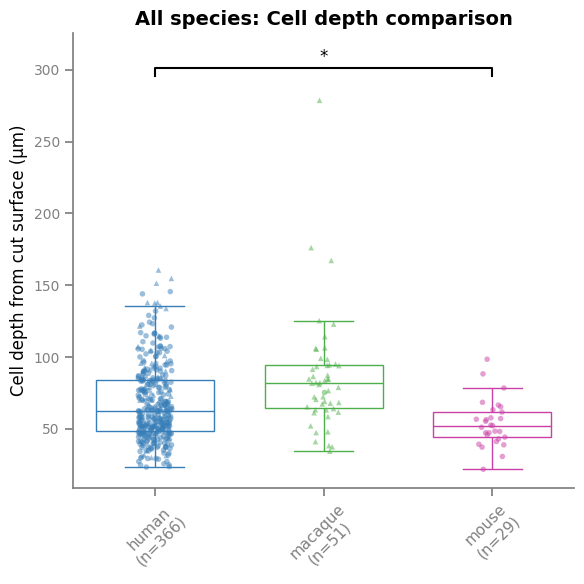


Saved: /root/capsule/scratch/20260807/slice_surface_depth/all_species_cell_depth_comparison.pdf
Saved: /root/capsule/scratch/20260807/slice_surface_depth/all_species_cell_depth_stats.csv


In [24]:
# Plot
fig, ax = plt.subplots(figsize=(6, 6))

# Plot stripplot with different markers for each method
for method, marker in [('lims', 'o'), ('estimated', '^')]:
    method_data = all_species_data[all_species_data['method'] == method]
    if len(method_data) > 0:
        sns.stripplot(data=method_data, x='species', y='cell_depth', hue='species',
                     palette=species_colors, order=species_order, legend=False,
                     alpha=0.5, size=4, ax=ax, marker=marker)

sns.boxplot(data=all_species_data, x='species', y='cell_depth', hue='species',
           palette=species_colors, order=species_order, legend=False,
           saturation=1, linewidth=1, width=0.7, showfliers=False, ax=ax)
format_box_plot(ax)

# Add statistical annotations from Dunn post-hoc test
if posthoc is not None:
    pairs = []
    pvals_annot = []
    for i, j in combinations(range(len(species_order)), 2):
        p = posthoc.iloc[i, j]
        if p < 0.05:
            pairs.append((species_order[i], species_order[j]))
            pvals_annot.append(p)
    
    if pairs:
        annotator = Annotator(ax, pairs, data=all_species_data, x='species', y='cell_depth', order=species_order)
        annotator.configure(test=None, text_format='star', loc='inside', color='black')
        annotator.set_pvalues(pvals_annot)
        annotator.annotate()

sns.despine(right=True, top=True)
ax.set_xlabel(None)
ax.set_ylabel('Cell depth from cut surface (µm)', rotation=90, size=12)
ax.set_title('All species: Cell depth comparison', size=14, weight='bold')
ax.tick_params(axis='x', rotation=45, labelsize=11)
ax.tick_params(axis='y', labelsize=10)

species_counts = all_species_data['species'].value_counts()
nobs = [f"{sp}\n(n={species_counts[sp]})" for sp in species_order]
ax.set_xticklabels(nobs, fontsize=11)

ax.tick_params(axis='both', colors='grey')
ax.xaxis.set_tick_params(labelcolor='grey')
ax.spines['bottom'].set_color('grey')
ax.spines['left'].set_color('grey')

plt.tight_layout()
plt.savefig(OUT_DIR / 'all_species_cell_depth_comparison.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Save statistics results instead of raw data
stats_df = pd.DataFrame(stats_results)
stats_df.to_csv(OUT_DIR / 'all_species_cell_depth_stats.csv', index=False)
print(f'\nSaved: {OUT_DIR / "all_species_cell_depth_comparison.pdf"}')
print(f'Saved: {OUT_DIR / "all_species_cell_depth_stats.csv"}')

## Analysis 3: L5 IT cells - cell_depth x species

In [14]:
# Filter to L5 IT only
l5it_data = all_data[all_data['subclass'] == 'L5 IT'].copy()
l5it_data = l5it_data.dropna(subset=['species', 'cell_depth'])

print(f'L5 IT data: {len(l5it_data)} cells')
print(f'\nSpecies counts:')
print(l5it_data['species'].value_counts())

L5 IT data: 83 cells

Species counts:
human      57
mouse      16
macaque    10
Name: species, dtype: int64


In [15]:
# Run stats
l5it_species_order = [s for s in species_order if s in l5it_data['species'].unique()]
l5it_groups = [l5it_data[l5it_data['species'] == sp]['cell_depth'].dropna().tolist()
               for sp in l5it_species_order]
l5it_groups = [g for g in l5it_groups if len(g) > 0]

stats_results = []  # Store statistics for CSV

if len(l5it_groups) > 2:
    stat, pval = kruskal(*l5it_groups, nan_policy='omit')

    # Store overall test result
    stats_results.append({
        'test': 'Kruskal-Wallis',
        'group1': 'all',
        'group2': 'all',
        'pval': pval,
        'pval_fdr': pval,
        'significant': pval < 0.05
    })

    print(f'Kruskal-Wallis test for L5 IT across species:')
    print(f'  Statistic: {stat:.4f}')
    print(f'  P-value: {pval:.4e}')

    if pval < 0.05:
        print(f'  => Significant difference detected')

        posthoc = sp.posthoc_dunn(l5it_groups, p_adjust='fdr_bh')
        print(f'\n  Posthoc Dunn test (FDR corrected):')

        for i, j in combinations(range(len(l5it_species_order)), 2):
            p = posthoc.iloc[i, j]
            stats_results.append({
                'test': 'Dunn posthoc (FDR)',
                'group1': l5it_species_order[i],
                'group2': l5it_species_order[j],
                'pval': p,
                'pval_fdr': p,
                'significant': p < 0.05
            })
            sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
            print(f'    {l5it_species_order[i]} vs {l5it_species_order[j]}: p = {p:.4e} {sig}')
    else:
        print(f'  => No significant difference')
elif len(l5it_groups) == 2:
    stat, pval = mannwhitneyu(l5it_groups[0], l5it_groups[1], nan_policy='omit')

    # Store test result
    stats_results.append({
        'test': 'Mann-Whitney U',
        'group1': l5it_species_order[0],
        'group2': l5it_species_order[1],
        'pval': pval,
        'pval_fdr': pval,
        'significant': pval < 0.05
    })

    print(f'Mann-Whitney U test for L5 IT:')
    print(f'  Statistic: {stat:.4f}')
    print(f'  P-value: {pval:.4e}')
    sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "ns"
    print(f'  {l5it_species_order[0]} vs {l5it_species_order[1]}: {sig}')

Kruskal-Wallis test for L5 IT across species:
  Statistic: 3.3118
  P-value: 1.9092e-01
  => No significant difference


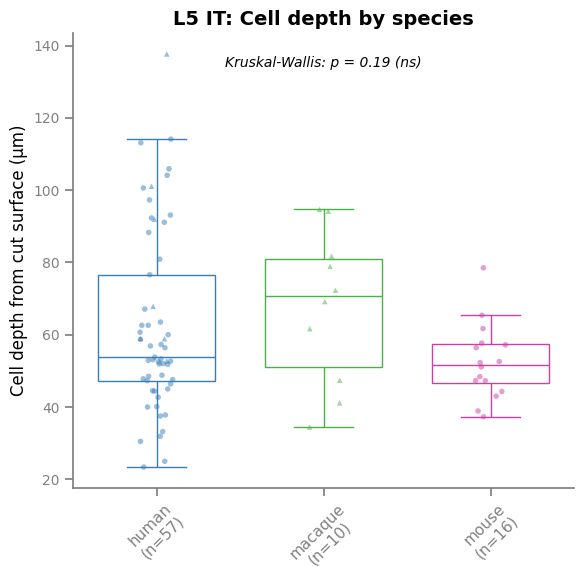


Saved: /root/capsule/scratch/20260807/slice_surface_depth/L5_IT_cell_depth_by_species.pdf
Saved: /root/capsule/scratch/20260807/slice_surface_depth/L5_IT_cell_depth_by_species_stats.csv


In [16]:
# Plot
fig, ax = plt.subplots(figsize=(6, 6))

# Plot stripplot with different markers for each method
for method, marker in [('lims', 'o'), ('estimated', '^')]:
    method_data = l5it_data[l5it_data['method'] == method]
    if len(method_data) > 0:
        sns.stripplot(data=method_data, x='species', y='cell_depth', hue='species',
                     palette=species_colors, order=l5it_species_order, legend=False,
                     alpha=0.5, size=4, ax=ax, marker=marker)

sns.boxplot(data=l5it_data, x='species', y='cell_depth', hue='species',
           palette=species_colors, order=l5it_species_order, legend=False,
           saturation=1, linewidth=1, width=0.7, showfliers=False, ax=ax)
format_box_plot(ax)

# Add text annotation for non-significant result
ax.text(0.5, 0.95, 'Kruskal-Wallis: p = 0.19 (ns)', 
        transform=ax.transAxes, ha='center', va='top',
        fontsize=10, color='black', style='italic')

sns.despine(right=True, top=True)
ax.set_xlabel(None)
ax.set_ylabel('Cell depth from cut surface (µm)', rotation=90, size=12)
ax.set_title('L5 IT: Cell depth by species', size=14, weight='bold')
ax.tick_params(axis='x', rotation=45, labelsize=11)
ax.tick_params(axis='y', labelsize=10)

l5it_counts = l5it_data['species'].value_counts()
nobs = [f"{sp}\n(n={l5it_counts[sp]})" for sp in l5it_species_order]
ax.set_xticklabels(nobs, fontsize=11)

ax.tick_params(axis='both', colors='grey')
ax.xaxis.set_tick_params(labelcolor='grey')
ax.spines['bottom'].set_color('grey')
ax.spines['left'].set_color('grey')

plt.tight_layout()
plt.savefig(OUT_DIR / 'L5_IT_cell_depth_by_species.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Save statistics results instead of raw data
stats_df = pd.DataFrame(stats_results)
stats_df.to_csv(OUT_DIR / 'L5_IT_cell_depth_by_species_stats.csv', index=False)
print(f'\nSaved: {OUT_DIR / "L5_IT_cell_depth_by_species.pdf"}')
print(f'Saved: {OUT_DIR / "L5_IT_cell_depth_by_species_stats.csv"}')

## Analysis 4: L5 ET cells - cell_depth x species

In [17]:
# Filter to L5 ET only
l5et_data = all_data[all_data['subclass'] == 'L5 ET'].copy()
l5et_data = l5et_data.dropna(subset=['species', 'cell_depth'])

print(f'L5 ET data: {len(l5et_data)} cells')
print(f'\nSpecies counts:')
print(l5et_data['species'].value_counts())

L5 ET data: 23 cells

Species counts:
macaque    14
human       6
mouse       3
Name: species, dtype: int64


In [18]:
# Run stats
l5et_species_order = [s for s in species_order if s in l5et_data['species'].unique()]
l5et_groups = [l5et_data[l5et_data['species'] == sp]['cell_depth'].dropna().tolist()
               for sp in l5et_species_order]
l5et_groups = [g for g in l5et_groups if len(g) > 0]

posthoc = None  # Initialize for plotting
stats_results = []  # Store statistics for CSV

if len(l5et_groups) > 2:
    stat, pval = kruskal(*l5et_groups, nan_policy='omit')

    # Store overall test result
    stats_results.append({
        'test': 'Kruskal-Wallis',
        'group1': 'all',
        'group2': 'all',
        'pval': pval,
        'pval_fdr': pval,
        'significant': pval < 0.05
    })

    print(f'Kruskal-Wallis test for L5 ET across species:')
    print(f'  Statistic: {stat:.4f}')
    print(f'  P-value: {pval:.4e}')

    if pval < 0.05:
        print(f'  => Significant difference detected')

        posthoc = sp.posthoc_dunn(l5et_groups, p_adjust='fdr_bh')
        print(f'\n  Posthoc Dunn test (FDR corrected):')

        for i, j in combinations(range(len(l5et_species_order)), 2):
            p = posthoc.iloc[i, j]
            stats_results.append({
                'test': 'Dunn posthoc (FDR)',
                'group1': l5et_species_order[i],
                'group2': l5et_species_order[j],
                'pval': p,
                'pval_fdr': p,
                'significant': p < 0.05
            })
            sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
            print(f'    {l5et_species_order[i]} vs {l5et_species_order[j]}: p = {p:.4e} {sig}')
    else:
        print(f'  => No significant difference')
elif len(l5et_groups) == 2:
    stat, pval = mannwhitneyu(l5et_groups[0], l5et_groups[1], nan_policy='omit')

    # Store test result
    stats_results.append({
        'test': 'Mann-Whitney U',
        'group1': l5et_species_order[0],
        'group2': l5et_species_order[1],
        'pval': pval,
        'pval_fdr': pval,
        'significant': pval < 0.05
    })

    print(f'Mann-Whitney U test for L5 ET:')
    print(f'  Statistic: {stat:.4f}')
    print(f'  P-value: {pval:.4e}')
    sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "ns"
    print(f'  {l5et_species_order[0]} vs {l5et_species_order[1]}: {sig}')

Kruskal-Wallis test for L5 ET across species:
  Statistic: 7.5414
  P-value: 2.3036e-02
  => Significant difference detected

  Posthoc Dunn test (FDR corrected):
    human vs macaque: p = 1.6718e-01 ns
    human vs mouse: p = 1.8129e-02 *
    macaque vs mouse: p = 6.9564e-02 ns


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

human vs. mouse: Custom statistical test, P_val:1.813e-02


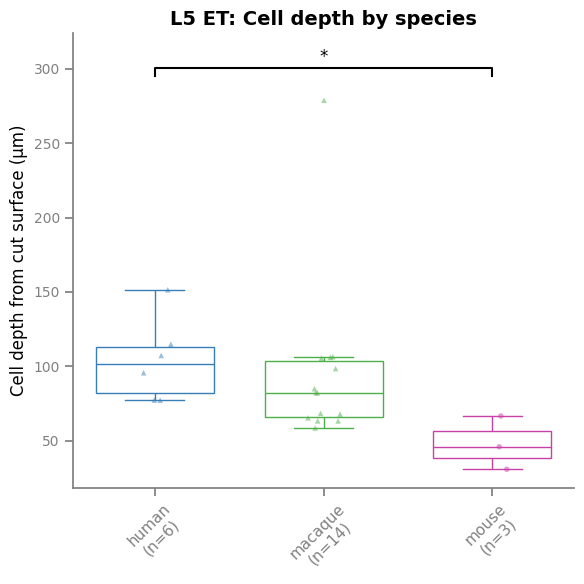


Saved: /root/capsule/scratch/20260807/slice_surface_depth/L5_ET_cell_depth_by_species.pdf
Saved: /root/capsule/scratch/20260807/slice_surface_depth/L5_ET_cell_depth_by_species_stats.csv


In [19]:
# Plot
fig, ax = plt.subplots(figsize=(6, 6))

# Plot stripplot with different markers for each method
for method, marker in [('lims', 'o'), ('estimated', '^')]:
    method_data = l5et_data[l5et_data['method'] == method]
    if len(method_data) > 0:
        sns.stripplot(data=method_data, x='species', y='cell_depth', hue='species',
                     palette=species_colors, order=l5et_species_order, legend=False,
                     alpha=0.5, size=4, ax=ax, marker=marker)

sns.boxplot(data=l5et_data, x='species', y='cell_depth', hue='species',
           palette=species_colors, order=l5et_species_order, legend=False,
           saturation=1, linewidth=1, width=0.7, showfliers=False, ax=ax)
format_box_plot(ax)

# Add statistical annotations from Dunn post-hoc test
if posthoc is not None:
    pairs = []
    pvals_annot = []
    for i, j in combinations(range(len(l5et_species_order)), 2):
        p = posthoc.iloc[i, j]
        if p < 0.05:
            pairs.append((l5et_species_order[i], l5et_species_order[j]))
            pvals_annot.append(p)
    
    if pairs:
        annotator = Annotator(ax, pairs, data=l5et_data, x='species', y='cell_depth', order=l5et_species_order)
        annotator.configure(test=None, text_format='star', loc='inside', color='black')
        annotator.set_pvalues(pvals_annot)
        annotator.annotate()

sns.despine(right=True, top=True)
ax.set_xlabel(None)
ax.set_ylabel('Cell depth from cut surface (µm)', rotation=90, size=12)
ax.set_title('L5 ET: Cell depth by species', size=14, weight='bold')
ax.tick_params(axis='x', rotation=45, labelsize=11)
ax.tick_params(axis='y', labelsize=10)

l5et_counts = l5et_data['species'].value_counts()
nobs = [f"{sp}\n(n={l5et_counts[sp]})" for sp in l5et_species_order]
ax.set_xticklabels(nobs, fontsize=11)

ax.tick_params(axis='both', colors='grey')
ax.xaxis.set_tick_params(labelcolor='grey')
ax.spines['bottom'].set_color('grey')
ax.spines['left'].set_color('grey')

plt.tight_layout()
plt.savefig(OUT_DIR / 'L5_ET_cell_depth_by_species.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Save statistics results instead of raw data
stats_df = pd.DataFrame(stats_results)
stats_df.to_csv(OUT_DIR / 'L5_ET_cell_depth_by_species_stats.csv', index=False)
print(f'\nSaved: {OUT_DIR / "L5_ET_cell_depth_by_species.pdf"}')
print(f'Saved: {OUT_DIR / "L5_ET_cell_depth_by_species_stats.csv"}')

## Summary statistics table

In [20]:
# Create summary statistics table
summary_data = []

# Analysis 1: Human by subclass
for subclass in human_subclass_order:
    vals = human_only[human_only['subclass'] == subclass]['cell_depth'].dropna()
    summary_data.append({
        'analysis': '1_human_by_subclass',
        'group': subclass,
        'n': len(vals),
        'mean': vals.mean(),
        'std': vals.std(),
        'median': vals.median(),
        'q25': vals.quantile(0.25),
        'q75': vals.quantile(0.75),
        'min': vals.min(),
        'max': vals.max()
    })

# Analysis 2: All species
for species in species_order:
    vals = all_species_data[all_species_data['species'] == species]['cell_depth'].dropna()
    summary_data.append({
        'analysis': '2_all_species',
        'group': species,
        'n': len(vals),
        'mean': vals.mean(),
        'std': vals.std(),
        'median': vals.median(),
        'q25': vals.quantile(0.25),
        'q75': vals.quantile(0.75),
        'min': vals.min(),
        'max': vals.max()
    })

# Analysis 3: L5 IT by species
for species in l5it_species_order:
    vals = l5it_data[l5it_data['species'] == species]['cell_depth'].dropna()
    summary_data.append({
        'analysis': '3_L5_IT_by_species',
        'group': species,
        'n': len(vals),
        'mean': vals.mean(),
        'std': vals.std(),
        'median': vals.median(),
        'q25': vals.quantile(0.25),
        'q75': vals.quantile(0.75),
        'min': vals.min(),
        'max': vals.max()
    })

# Analysis 4: L5 ET by species
for species in l5et_species_order:
    vals = l5et_data[l5et_data['species'] == species]['cell_depth'].dropna()
    summary_data.append({
        'analysis': '4_L5_ET_by_species',
        'group': species,
        'n': len(vals),
        'mean': vals.mean(),
        'std': vals.std(),
        'median': vals.median(),
        'q25': vals.quantile(0.25),
        'q75': vals.quantile(0.75),
        'min': vals.min(),
        'max': vals.max()
    })

summary_df = pd.DataFrame(summary_data)
summary_df.to_csv(OUT_DIR / 'summary_statistics.csv', index=False)

print('Summary statistics:')
print(summary_df.to_string())
print(f'\nSaved: {OUT_DIR / "summary_statistics.csv"}')

Summary statistics:
               analysis       group    n        mean        std      median        q25         q75        min         max
0   1_human_by_subclass     L2/3 IT  148   72.898204  24.753829   70.165469  55.000000   86.290791  25.700000  160.635115
1   1_human_by_subclass       L4 IT   78   50.585183  13.001943   50.350000  41.600000   57.150000  27.300000  107.300000
2   1_human_by_subclass       L5 IT   57   62.610728  25.061482   53.800000  47.300000   76.600000  23.400000  137.657230
3   1_human_by_subclass     L5/6 NP   19   71.389474  30.452967   75.900000  42.650000   95.850000  24.900000  116.600000
4   1_human_by_subclass  L6 IT Car3   17   71.623062  35.288658   63.900000  44.400000   78.649751  35.200000  145.600000
5   1_human_by_subclass       L6 IT   17   76.503481  26.192518   79.800000  49.800000   87.000000  34.900000  135.483871
6   1_human_by_subclass       L6 CT   12   89.383333  28.288990   86.250000  62.950000  118.050000  45.800000  127.300000
7   

In [21]:
print('='*80)
print('=== Analysis complete ===')
print('='*80)
print(f'\nAll results saved to: {OUT_DIR}')
print(f'\nGenerated files:')
for f in sorted(OUT_DIR.glob('*')):
    print(f'  - {f.name}')

=== Analysis complete ===

All results saved to: /root/capsule/scratch/20260807/slice_surface_depth

Generated files:
  - L5_ET_cell_depth_by_species.pdf
  - L5_ET_cell_depth_by_species_data.csv
  - L5_ET_cell_depth_by_species_stats.csv
  - L5_IT_cell_depth_by_species.pdf
  - L5_IT_cell_depth_by_species_data.csv
  - L5_IT_cell_depth_by_species_stats.csv
  - all_species_cell_depth_comparison.pdf
  - all_species_cell_depth_data.csv
  - all_species_cell_depth_stats.csv
  - human_cell_depth_by_subclass.pdf
  - human_cell_depth_by_subclass_data.csv
  - human_cell_depth_by_subclass_stats.csv
  - summary_statistics.csv
